In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN


In [4]:
datos = pd.read_csv("rmcab_pm25_2009_2015.csv")

In [5]:
datos.columns

Index(['fecha', 'zona', 'estacion', 'unidades', 'pm25_24h', 'hora_24h',
       'pm25_1h', 'hora_1h'],
      dtype='str')

In [6]:
datos.describe()

,pm25_24h,pm25_1h
count,11804.000000,12366.000000
mean,23.430540,40.705070
std,12.437457,23.540721
min,2.600000,0.000000
25%,13.800000,23.300000
50%,21.400000,36.700000
75%,31.400000,53.500000
max,98.600000,315.000000


In [7]:
datos["pm25_24h"].isna()

0         True
1        False
2         True
3        False
4        False
         ...  
27342     True
27343     True
27344    False
27345    False
27346    False
Name: pm25_24h, Length: 27347, dtype: bool

In [8]:
datos.head(15)

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h
0,2009-04-01,WEST,Carvajal - Sevillana,µg/m³,NaN,NaN,NaN,NaN
1,2009-04-01,CENTRAL,Centro de Alto Rendimiento,µg/m³,21.6,01 a.m.,31.4,09 a.m.
2,2009-04-01,NORTH,Guaymaral,µg/m³,NaN,NaN,NaN,NaN
3,2009-04-01,WEST,Kennedy,µg/m³,43.4,01 a.m.,72.7,08 a.m.
4,2009-04-01,NORTH,Las Ferias,µg/m³,22.4,01 a.m.,33.4,07 a.m.
5,2009-04-01,NORTH,MinAmbiente,µg/m³,NaN,NaN,NaN,NaN
6,2009-04-01,WEST,Puente Aranda,µg/m³,NaN,NaN,NaN,NaN
7,2009-04-01,NORTH,Suba,µg/m³,NaN,NaN,NaN,NaN
8,2009-04-01,SOUTH,Tunal,µg/m³,34.6,01 a.m.,68.0,09 a.m.
9,2009-04-01,NORTH,Usaquen,µg/m³,18.9,07 p.m.,32.8,08 a.m.


Convierto la columna fecha al formato correcto y elimino valores nulos

In [25]:
datos["fecha"] = pd.to_datetime(datos["fecha"])
datos_validos = datos.dropna(subset=["pm25_24h"])

Hay datos extrañamente altos, como por día se toman más de 4 datos, se excluirán los datos que no tengan 4 registros en un radio adecuado al rededor de ellos 

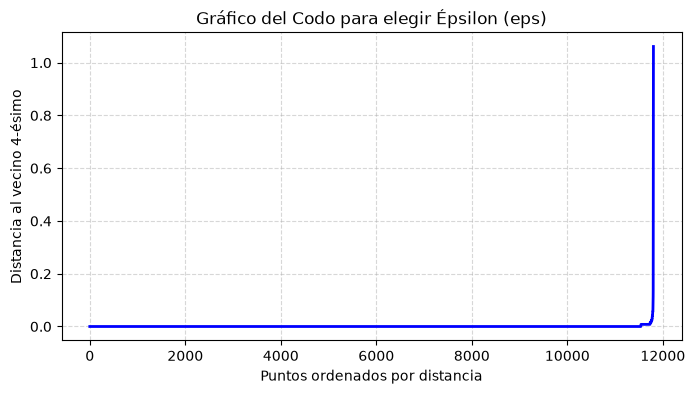

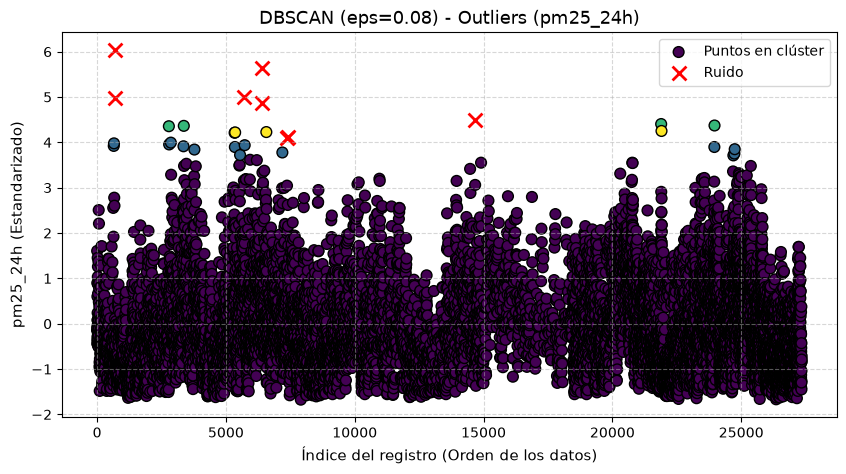

Cantidad de outliers detectados: 8

-- Registros con valores atípicos de pm25_24h --


,pm25_24h
683,98.6
693,85.4
5719,85.5
6399,93.7
6409,84.0
7381,74.5
7391,74.7
14686,79.4


In [28]:
from sklearn.neighbors import NearestNeighbors

# Escalar los datos
X_scaled = StandardScaler().fit_transform(datos_validos[['pm25_24h']])

min_samples = 4 # deben haber 4 o más estaciones con medicion similar

# Calcular distancias al vecino más cercano número 4
nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distancias, _ = nbrs.kneighbors(X_scaled)

# Ordenar las distancias del vecino más lejano de menor a mayor
distancias_k = np.sort(distancias[:, min_samples - 1])

# Graficar el codo para elegir EPS
plt.figure(figsize=(8, 4))
plt.plot(distancias_k, color='blue', lw=2)
plt.title("Gráfico del Codo para elegir Épsilon (eps)", fontsize=12)
plt.xlabel("Puntos ordenados por distancia", fontsize=10)
plt.ylabel(f"Distancia al vecino {min_samples}-ésimo", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Confiburación de dbscan
eps_elegido = 0.08  #elegido por codo
dbscan = DBSCAN(eps=eps_elegido, min_samples=min_samples)
clusters = dbscan.fit_predict(X_scaled)

# Guardar los resultados en una copia limpia del DataFrame original
datos_validos = datos_validos.copy()
datos_validos['Cluster'] = clusters

# Separar los puntos normales del ruido
noise_mask = (clusters == -1)

#Gráfico de resultados
plt.figure(figsize=(10, 5))

# Puntos que pertenecen a un clúster (Normales)
plt.scatter(datos_validos[~noise_mask].index, X_scaled[~noise_mask, 0],
            c=clusters[~noise_mask], cmap='viridis', s=60, 
            edgecolors='k', label='Puntos en clúster')

# Puntos identificados como Ruido / Outliers (en rojo)
plt.scatter(datos_validos[noise_mask].index, X_scaled[noise_mask, 0],
            color='red', marker='x', s=100, linewidths=2, 
            label='Ruido')

plt.title(f"DBSCAN (eps={eps_elegido}) - Outliers (pm25_24h)", fontsize=13)
plt.xlabel("Índice del registro (Orden de los datos)", fontsize=11)
plt.ylabel("pm25_24h (Estandarizado)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.show()

# ==========================================
# 4. Mostrar los resultados de los Outliers
# ==========================================
outliers_dbscan = datos_validos[datos_validos['Cluster'] == -1]

print(f"Cantidad de outliers detectados: {len(outliers_dbscan)}")
print("\n-- Registros con valores atípicos de pm25_24h --")
# Si estás en Jupyter Notebook / Google Colab se mostrará con estilo de tabla
display(outliers_dbscan[['pm25_24h']])


La mayoría de outliers se encuentran en Kennedy. Consultar si eliminarlos por no estar en un grupo, o conservarlos. También se puede evaluar cómo funciona el modelo de ambas formas, eliminando los datos mayores que 90

In [29]:
outliers_dbscan

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h,Cluster
683,2009-06-09,WEST,Puente Aranda,µg/m³,98.6,12 p.m.,271.8,08 a.m.,-1
693,2009-06-10,WEST,Puente Aranda,µg/m³,85.4,01 a.m.,141.7,09 a.m.,-1
5719,2010-10-01,WEST,Kennedy,µg/m³,85.5,05 p.m.,180.0,07 a.m.,-1
6399,2010-12-08,WEST,Kennedy,µg/m³,93.7,06 p.m.,136.8,01 a.m.,-1
6409,2010-12-09,WEST,Kennedy,µg/m³,84.0,03 a.m.,149.0,01 a.m.,-1
7381,2011-03-17,WEST,Kennedy,µg/m³,74.5,11 p.m.,94.5,10 p.m.,-1
7391,2011-03-18,WEST,Kennedy,µg/m³,74.7,11 a.m.,126.3,09 a.m.,-1
14686,2012-12-08,WEST,Kennedy,µg/m³,79.4,07 a.m.,136.0,01 a.m.,-1


Fijo la fila (estación) de mayor promedio diario (mayor número en pm25_24h)

In [43]:
datos_limpios = datos_validos[datos_validos['Cluster'] == 0]
filas_maximas = datos_limpios.loc[datos_limpios.groupby("fecha")["pm25_24h"].idxmax()].drop(columns=["Cluster"])
filas_maximas = filas_maximas.sort_values(by="fecha").reset_index(drop=True)
filas_maximas

,fecha,zona,estacion,unidades,pm25_24h,hora_24h,pm25_1h,hora_1h
0,2009-04-01,WEST,Kennedy,µg/m³,43.4,01 a.m.,72.7,08 a.m.
1,2009-04-02,WEST,Kennedy,µg/m³,30.9,01 a.m.,39.7,11 p.m.
2,2009-04-03,WEST,Kennedy,µg/m³,41.5,04 p.m.,74.7,07 a.m.
3,2009-04-04,WEST,Kennedy,µg/m³,39.1,01 a.m.,34.3,09 a.m.
4,2009-04-05,WEST,Kennedy,µg/m³,34.1,12 a.m.,56.3,08 a.m.
...,...,...,...,...,...,...,...,...
2333,2015-08-27,WEST,Movil 7ma,µg/m³,41.5,12 p.m.,76.0,12 p.m.
2334,2015-08-28,WEST,Carvajal - Sevillana,µg/m³,39.2,01 a.m.,44.7,01 p.m.
2335,2015-08-29,WEST,Carvajal - Sevillana,µg/m³,32.3,01 a.m.,32.7,03 p.m.
2336,2015-08-30,WEST,Carvajal - Sevillana,µg/m³,26.6,05 a.m.,27.6,04 p.m.


Grafico todas las concentraciones promedio máximas diarias 

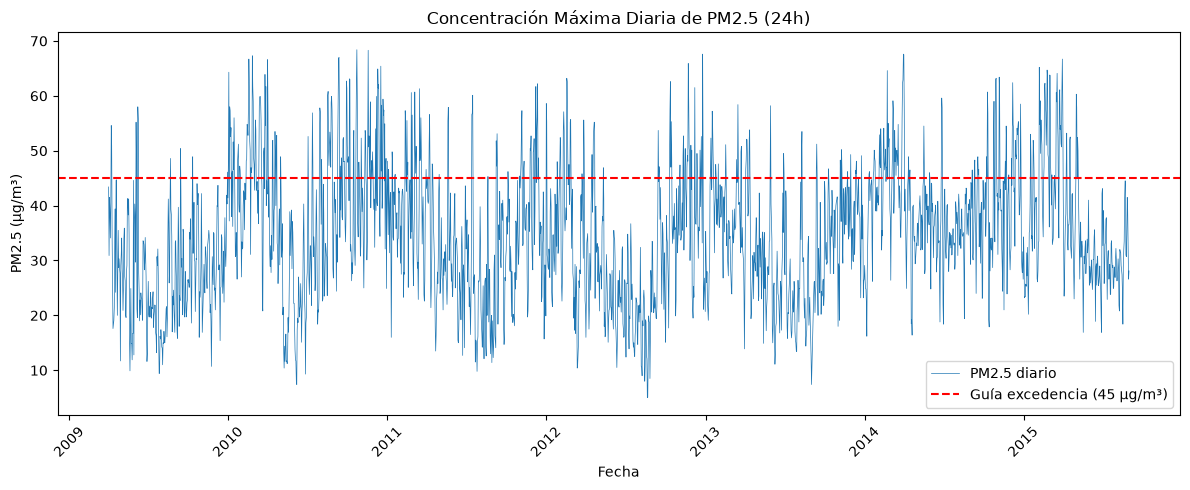

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(filas_maximas['fecha'], filas_maximas['pm25_24h'], linewidth=0.5, label='PM2.5 diario')

# Línea de referencia
plt.axhline(y=45, color='r', linestyle='--', label='Guía excedencia (45 µg/m³)')

# Personalización
plt.title('Concentración Máxima Diaria de PM2.5 (24h)')
plt.xlabel('Fecha')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

In [45]:
filas_maximas.describe()

,fecha,pm25_24h,pm25_1h
count,2338,2338.000000,2334.000000
mean,2012-06-14 17:30:44.653550,34.686399,60.280763
min,2009-04-01 00:00:00,5.000000,9.800000
25%,2010-11-06 06:00:00,26.125000,42.000000
50%,2012-06-13 12:00:00,33.900000,56.600000
75%,2014-01-23 18:00:00,42.600000,74.875000
max,2015-08-31 00:00:00,68.400000,315.000000
std,NaN,11.947177,25.684533


Establezco las excedencias con umbral 50, y grafico

(array([13879., 14245., 14610., 14975., 15340., 15706., 16071., 16436.]),
 [Text(13879.0, 0, '2008'),
  Text(14245.0, 0, '2009'),
  Text(14610.0, 0, '2010'),
  Text(14975.0, 0, '2011'),
  Text(15340.0, 0, '2012'),
  Text(15706.0, 0, '2013'),
  Text(16071.0, 0, '2014'),
  Text(16436.0, 0, '2015')])

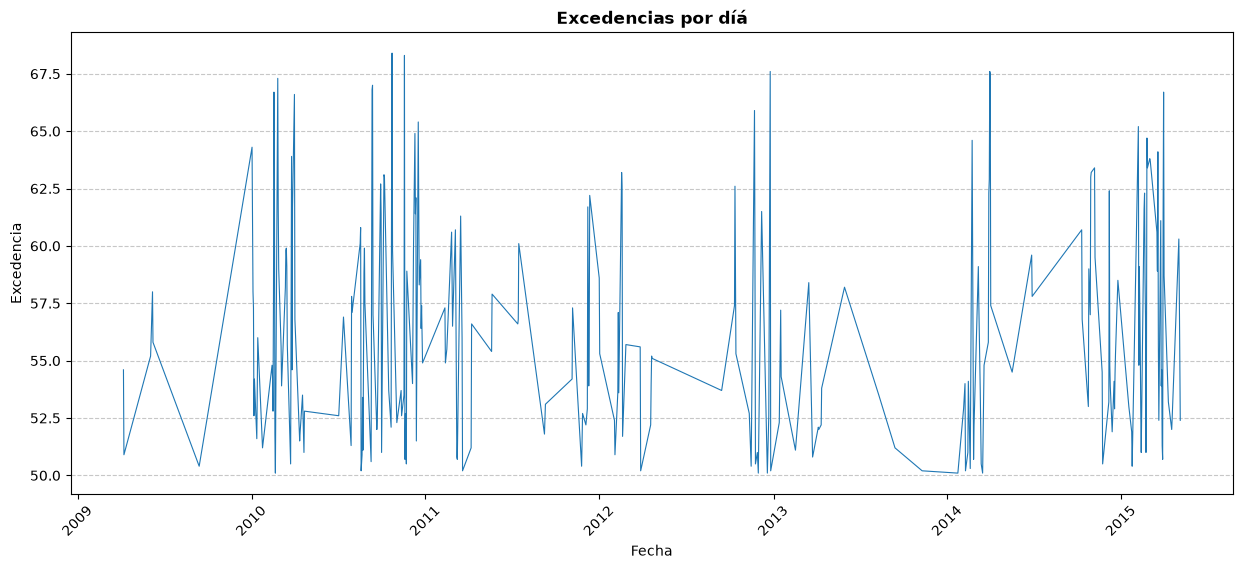

In [56]:
excedencias = filas_maximas[filas_maximas['pm25_24h']>50]

plt.figure(figsize=(15, 6))
plt.plot(excedencias["fecha"],excedencias["pm25_24h"], linewidth = 0.8)
plt.title('Excedencias por díá',fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Excedencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

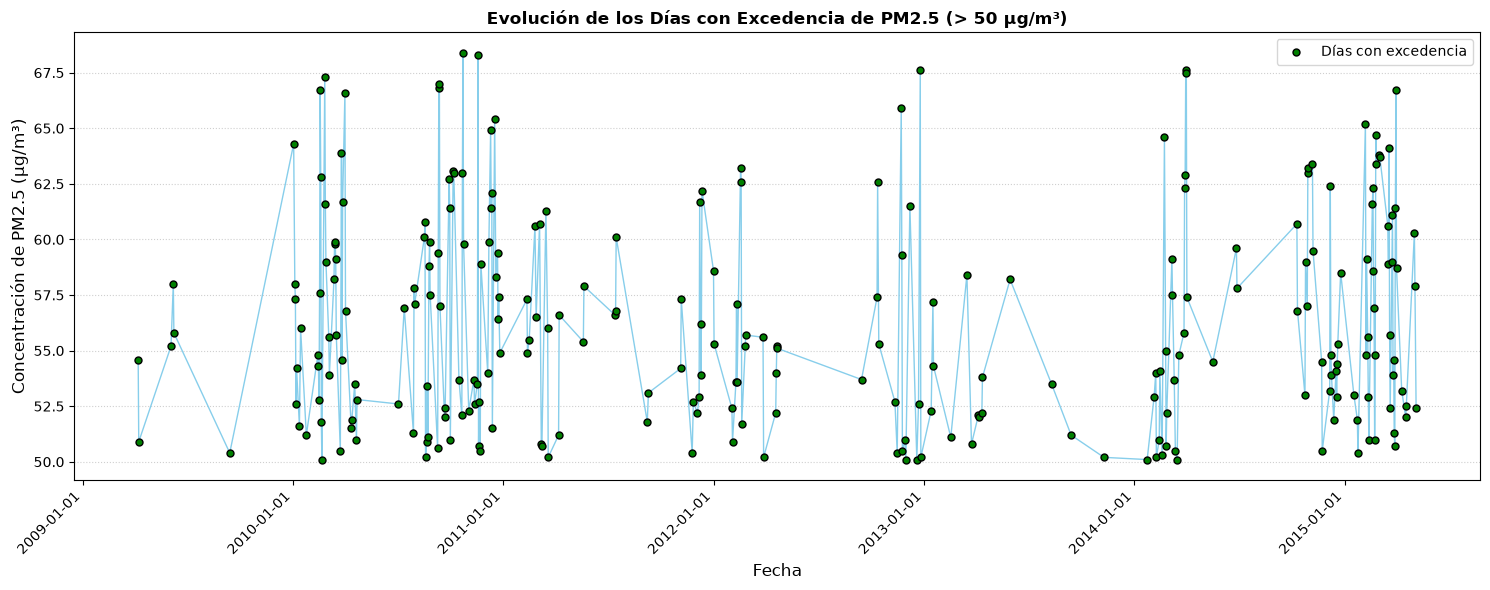

In [57]:

import matplotlib.dates as mdates

plt.figure(figsize=(15, 6))
plt.plot(excedencias["fecha"], excedencias["pm25_24h"], color='skyblue', linewidth=1, zorder=2)
plt.scatter(excedencias["fecha"], excedencias["pm25_24h"], color='green', edgecolors='black', s=25, zorder=3, label='Días con excedencia')

# Títulos y etiquetas descriptivas
plt.title('Evolución de los Días con Excedencia de PM2.5 (> 50 µg/m³)', fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Concentración de PM2.5 (µg/m³)', fontsize=12)

# Formateador inteligente para el eje X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45, ha='right')

# Detalles visuales adicionales
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


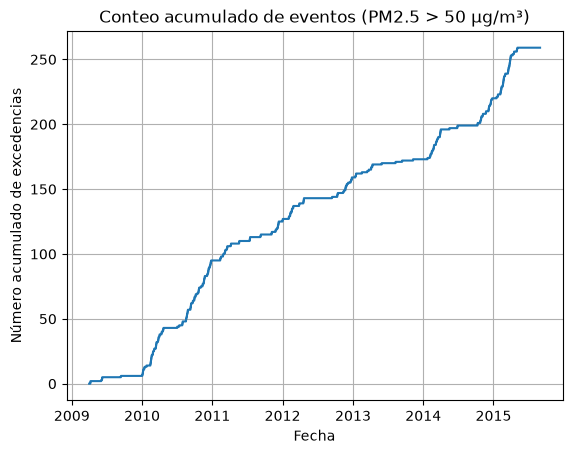

In [58]:
filas_maximas['excedencias_acumuladas'] = (filas_maximas['pm25_24h'] > 50).astype(int).cumsum()

plt.plot(filas_maximas["fecha"], filas_maximas['excedencias_acumuladas'], drawstyle='steps-post')
plt.xlabel("Fecha")
plt.ylabel("Número acumulado de excedencias")
plt.title("Conteo acumulado de eventos (PM2.5 > 50 µg/m³)")
plt.grid(True)
plt.show()

In [60]:
excedencias.to_csv("excedencias_pm25.csv", index=False)


Ya hicimos la limpieeza y organización de los datos, lo siguiente será exportar la base de datos a R para ejecutar el modelo inicial de Edy con los datos reales. Podemos hacerlo inicialmente a la estimación por kernel, o implementarlo directammente a la esstimación con árboles bayesianos